# Descubrimiento de conocimiento: inducción de reglas mediante SOM, TDIDT y redes bayesianas

Implementación de un flujo integral de Descubrimiento de Conocimiento en Bases de Datos (KDD, *Knowledge Discovery in Databases*) sobre el conjunto de datos `data/AdultosyJovenesDatosTrab.xls` (147 observaciones multidimensionales de perfiles sociolaborales). El objetivo metodológico consiste en integrar tres paradigmas computacionales complementarios para transformar datos heterogéneos en conocimiento operativo y probabilísticamente fundamentado:

1. **Mapas Autoorganizados de Kohonen (SOM)** mediante `minisom`: aprendizaje no supervisado y competitivo para proyectar el espacio de atributos sobre un retículo bidimensional regular, preservando relaciones topológicas de vecindad y aislando agrupamientos latentes naturales sin supervisión externa.
2. **Árboles de Decisión (TDIDT / C4.5 / CART)** mediante `scikit-learn`: aprendizaje supervisado simbólico que utiliza la pertenencia a los grupos inducidos por el SOM como clase objetivo, extrayendo reglas de clasificación explícitas, auditables y estructuradas bajo lógica proposicional SI-ENTONCES.
3. **Modelos Gráficos Probabilísticos (Redes Bayesianas)** mediante `pgmpy`: formalismo causal y probabilístico que modela la distribución conjunta factorizada del dominio, permitiendo cuantificar la incertidumbre, ponderar la fuerza evidencial de las reglas extraídas y resolver consultas de inferencia predictiva y diagnóstica.

El desarrollo se formula bajo estándares rigurosos de ingeniería de software y análisis de datos: no se asumen relaciones arbitrarias, se detallan los fundamentos algebraicos e informacionales de cada técnica, se exponen explícitamente los supuestos que deben cumplirse y se analiza el costo computacional involucrado. Requisitos: Python 3.10 o superior, numpy, pandas, matplotlib, seaborn, minisom, scikit-learn, networkx y pgmpy. La ejecución utiliza la semilla pseudoaleatoria fija 42 para garantizar reproducibilidad exacta.

## 1. Alcance, aplicabilidad y justificación metodológica

El descubrimiento de patrones en ingeniería de datos demanda conciliar dos requisitos habitualmente contrapuestos: la capacidad de modelar estructuras complejas no lineales en alta dimensión y la necesidad de interpretabilidad humana para la toma de decisiones. El pipeline propuesto desacopla el problema en tres etapas secuenciales:

```
[Datos Integrados] ──> [SOM: Agrupamiento No Supervisado] ──> [Grupos Latentes]
                                                                     │
[Reglas Ponderadas] <── [Red Bayesiana: Cuantificación] <── [TDIDT: Inducción de Reglas]
```

### Cuándo conviene utilizar Mapas Autoorganizados (SOM)

El SOM resulta la técnica adecuada cuando:
- No se dispone de una variable objetivo etiquetada previamente y se requiere identificar agrupamientos naturales basados en similitud multidimensional.
- La dimensionalidad del espacio de atributos impide la inspección directa y se necesita una reducción dimensional no lineal a una grilla discreta 2D conservando la métrica de vecindad.
- Los datos presentan topologías complejas o distribuciones multimodales donde algoritmos paramétricos (como K-Means o Mezclas Gaussianas) fallan por su supuesto implícito de hiperesferas convexas o varianzas homogéneas.
- Se requiere cuantización vectorial para derivar vectores prototipo (neuronas) que actúen como centroides representativos de subpoblaciones densas.

Casos donde el SOM no constituye la herramienta indicada:
- Se requiere formular directamente fronteras de decisión paramétricas supervisadas o funciones de pérdida con optimización de márgenes (enfoque propio de Support Vector Machines o clasificadores lineales).
- El volumen de datos es extremadamente reducido respecto al número de dimensiones, lo que provoca subajuste topológico y neuronas desiertas.
- Se precisa una inferencia probabilística sobre la pertenencia a clusters (un SOM genera cuantización geométrica determinística, no probabilidades directas de membresía).

### Qué información entrega el modelo SOM

El entrenamiento del SOM produce representaciones analíticas fundamentales:
- **Vectores de pesos sinápticos ($W_i \in \mathbb{R}^D$)**: Prototipos multidimensionales en el espacio original de variables que sintetizan cada región del mapa.
- **Best Matching Unit (BMU)**: Mapeo discreto de cada registro al nodo de menor distancia euclídea en la retícula.
- **U-Matrix (Unified Distance Matrix)**: Matriz de distancias locales entre neuronas contiguas en la grilla. Las regiones con valores bajos representan núcleos de alta densidad intra-cluster, mientras que las crestas con valores elevados señalan fronteras y discontinuidades naturales entre grupos.
- **Hit Map (Densidad de activación)**: Frecuencia de patrones asignados a cada neurona, lo que permite verificar el balance del mapa y detectar neuronas inactivas o muertas.
- **Component Planes (Planos de componentes)**: Proyección individual de cada variable sobre la topología del mapa, revelando de forma visual correlaciones monotónicas directas o inversas entre atributos.
- **Métricas de calidad geométrica y topológica**: *Quantization Error* (fidelidad de aproximación métrica) y *Topographic Error* (proporción de patrones cuya segunda BMU no es vecina inmediata en la retícula).

### Justificación de la integración SOM + TDIDT + Redes Bayesianas

- **Del SOM al TDIDT**: El SOM particiona el espacio de observaciones pero se comporta como un modelo de caja gris: asigna patrones a coordenadas $(i, j)$ sin entregar una justificación explicativa en el lenguaje del dominio. Al tomar la coordenada o grupo resultante como variable de clase objetivo, el algoritmo TDIDT formula divisiones ortogonales (*axis-aligned splits*) y construye un árbol de decisión equivalente a un conjunto de reglas proposicionales SI-ENTONCES, perfectamente comprensibles para un operador humano o un motor de reglas.
- **Del TDIDT a la Red Bayesiana**: Las reglas de decisión generadas por TDIDT son de naturaleza puramente determinista y local (cada camino representa una secuencia de condiciones fijas). La Red Bayesiana integra esas dependencias en un grafo acíclico dirigido probabilístico (DAG). De este modo, se calcula la incidencia relativa de cada premisa, se resuelve la clasificación ante evidencia parcial o incompleta y se obtiene la probabilidad condicional a posteriori $P(\text{Grupo} \mid \text{Regla})$, cuantificando la robustez y certidumbre del patrón descubierto.

## 2. Marco teórico y formulación matemática

### 2.1 Mapas Autoorganizados de Kohonen

Sea $\mathcal{X} = \{x_k\}_{k=1}^N \subset \mathbb{R}^D$ el conjunto de patrones de entrada normalizados. La red consta de una grilla bidimensional de $M$ neuronas indexadas por su posición discreta $r_i \in \mathbb{Z}^2$, cada una asociada a un vector de pesos $W_i = [w_{i1}, w_{i2}, \dots, w_{iD}]^T \in \mathbb{R}^D$.

#### Selección de la BMU (Best Matching Unit)
Para cada patrón $x$, la neurona ganadora $c(x)$ se define según la métrica euclídea mínima:

$$c(x) = \arg\min_{i \in \{1, \dots, M\}} \| x - W_i \|_2 = \arg\min_i \sqrt{\sum_{j=1}^D (x_j - w_{ij})^2}$$

#### Función de vecindad y adaptación cooperativa
El aprendizaje es competitivo en la selección de la BMU y cooperativo en la actualización de pesos. La influencia sobre las neuronas adyacentes decae espacialmente según un núcleo gaussiano:

$$h_{ci}(t) = \exp\left(-\frac{\| r_c - r_i \|_2^2}{2\sigma(t)^2}\right)$$

donde $\| r_c - r_i \|_2$ es la distancia espacial sobre la grilla y $\sigma(t)$ es el radio de vecindad en la época $t$.

#### Dinámica de actualización de pesos
Los vectores de pesos se corrigen iterativamente hacia el patrón de entrada:

$$W_i(t+1) = W_i(t) + \alpha(t)\, h_{ci}(t)\, \bigl(x - W_i(t)\bigr)$$

con la tasa de aprendizaje $\alpha(t)$ y el radio $\sigma(t)$ sujetos a regímenes de decaimiento monótono decreciente:

$$\alpha(t) = \alpha_0 \left(1 - \frac{t}{T}\right), \qquad \sigma(t) = \sigma_0 \left(1 - \frac{t}{T}\right)$$

#### Métricas de evaluación de la representación
- **Error de cuantización ($QE$)**: Distancia media entre cada patrón y el prototipo de su BMU:
  $$QE = \frac{1}{N} \sum_{k=1}^N \| x_k - W_{c(x_k)} \|_2$$
- **Error topológico ($TE$)**: Proporción de patrones cuya primera y segunda neurona más cercanas en el espacio de datos no son vecinas topológicas adyacentes sobre la grilla:
  $$TE = \frac{1}{N} \sum_{k=1}^N \mathbb{1}\bigl[ \| r_{c_1(x_k)} - r_{c_2(x_k)} \|_1 > 1 \bigr]$$

---

### 2.2 Inducción de Árboles de Decisión (TDIDT)

Sea $S$ un conjunto de ejemplos de entrenamiento rotulados con las clases de grupo $G \in \{G_1, \dots, G_C\}$ generadas por el SOM.

#### Entropía de Shannon
La incertidumbre sobre la pertenencia de clase en el nodo actual se cuantifica mediante la entropía:

$$H(S) = -\sum_{j=1}^C p_j \log_2(p_j)$$

donde $p_j$ representa la proporción empírica de muestras pertenecientes al grupo $G_j$ en el subconjunto $S$. Por convención, $0 \log_2 0 = 0$.

#### Ganancia de información
Al particionar el conjunto $S$ mediante un atributo o condición de corte $A$, la reducción neta esperada de entropía se expresa como:

$$\mathrm{Gain}(S, A) = H(S) - \sum_{v \in \mathrm{Valores}(A)} \frac{|S_v|}{|S|} H(S_v)$$

El algoritmo evalúa exhaustivamente todas las particiones admisibles y selecciona en cada bifurcación aquella que maximice $\mathrm{Gain}(S, A)$.

#### Formalización de reglas proposicionales
Cada trayectoria que desciende desde la raíz hasta un nodo hoja $l$ induce de forma unívoca una regla de inferencia lógica:

$$R_l: \quad \left( \bigwedge_{m=1}^{K_l} \bigl(A_{m} \odot v_{m}\bigr) \right) \implies G = G^*_l$$

donde $\odot \in \{=, \le, >\}$, $K_l$ es la profundidad del camino y $G^*_l$ es la clase mayoritaria en la hoja.

---

### 2.3 Redes Bayesianas y Ponderación Probabilística

Una Red Bayesiana es un modelo probabilístico gráfico definido por un Grafo Dirigido Acíclico (DAG) $\mathcal{G} = (\mathcal{V}, \mathcal{E})$ y un conjunto de distribuciones condicionales parametrizadas $\Theta$. Cada nodo $X_i \in \mathcal{V}$ representa una variable aleatoria discreta, y las aristas dirigidas $(X_j, X_i) \in \mathcal{E}$ codifican dependencias estadísticas directas, designando a $X_j \in \mathrm{Padres}(X_i)$.

#### Factorización de la distribución conjunta
En virtud de la propiedad de Markov local (cada variable es condicionalmente independiente de sus no descendientes dado sus padres), la distribución de probabilidad conjunta sobre el conjunto completo de variables $\mathbf{X} = \{X_1, \dots, X_n\}$ factoriza como el producto de las Tablas de Probabilidad Condicional (CPT):

$$P(X_1 = x_1, \dots, X_n = x_n) = \prod_{i=1}^n P\bigl(X_i = x_i \mid \mathrm{Padres}(X_i) = \pi_i\bigr)$$

#### Estimación bayesiana de parámetros (Regularización Dirichlet / BDeu)
Para prevenir el colapso de probabilidades condicionales a cero ante combinaciones de atributos no observadas en muestras finitas, se aplica un estimador Bayesiano con a priori de Dirichlet simétrico (BDeu):

$$P(X_i = k \mid \mathrm{Padres}(X_i) = j) = \frac{N_{ijk} + \frac{\alpha}{r_i \cdot q_i}}{\sum_{k'=1}^{r_i} \left( N_{ijk'} + \frac{\alpha}{r_i \cdot q_i} \right)}$$

donde $N_{ijk}$ es la cuenta muestral, $r_i$ es la cardinalidad de $X_i$, $q_i$ es el número de configuraciones de sus padres y $\alpha$ representa el tamaño de muestra equivalente del a priori.

#### Ponderación evidencial de una regla
Dada una regla inducida $R: \mathbf{C} \implies G_k$, donde $\mathbf{C} = \{X_{j_1} = v_{j_1}, \dots, X_{j_m} = v_{j_m}\}$ representa el antecedente o conjunto de premisas, la red bayesiana calcula formalmente la probabilidad posterior de pertenencia mediante el algoritmo exacto de Eliminación de Variables:

$$P(G = G_k \mid \mathbf{C}) = \frac{P(G = G_k, \mathbf{C})}{P(\mathbf{C})} = \frac{\sum_{\mathbf{Z}} P(G = G_k, \mathbf{C}, \mathbf{Z})}{\sum_{G'} \sum_{\mathbf{Z}} P(G', \mathbf{C}, \mathbf{Z})}$$

donde $\mathbf{Z} = \mathcal{V} \setminus (\{G\} \cup \mathrm{Var}(\mathbf{C}))$ denota el conjunto de variables latentes sobre las cuales se marginaliza.

---

### 2.4 Supuestos metodológicos

1. **Normalización dimensional acotada**: El cómputo de la distancia euclídea en el SOM exige que todas las variables estén reescaladas uniformemente al intervalo $[0, 1]$. Sin este preprocesamiento, los atributos con mayor escala numérica sesgan la topología del mapa.
2. **Independencia condicional y aciclicidad**: La topología de la Red Bayesiana debe satisfacer formalmente la condición de aciclicidad (DAG). Las independencias condicionales asumidas reflejan la estructura causal o de dependencia directa verificada entre variables predictivas y el grupo resultante.
3. **Representatividad muestral**: Se asume que las 147 observaciones capturan la variabilidad sociodemográfica del dominio en estudio sin sesgos de muestreo sistemáticos.
4. **Regularización bayesiana en CPTs**: La inferencia no contempla probabilidades cero absolutas para configuraciones factibles del dominio; las celdas no observadas se amortiguan mediante regularización de Dirichlet para preservar la generalización.
5. **Criterio de corte determinista en TDIDT**: La partición de atributos en el árbol es exhaustiva y libre de marcha atrás (*greedy*), optimizando el criterio de entropía para maximizar la pureza por hoja.

---

### 2.5 Análisis de complejidad computacional

- **SOM (minisom)**: El entrenamiento requiere $\mathcal{O}(T \cdot N \cdot M \cdot D)$, donde $T$ es el número de épocas, $N$ es la cantidad de registros ($147$), $M$ el número de neuronas de la grilla ($2 \times 3 = 6$) y $D$ la dimensión del vector de características ($7$). Para $1000$ iteraciones, la ejecución insume fracciones de segundo.
- **TDIDT (scikit-learn)**: La construcción del árbol de decisión opera en $\mathcal{O}(D \cdot N \log N)$ en cada nivel de profundidad, con una cota total acotada por $\mathcal{O}(D \cdot N \log N \cdot \text{profundidad})$.
- **Red Bayesiana (pgmpy)**: La inferencia exacta por eliminación de variables tiene complejidad $\mathcal{O}(V \cdot d^{w+1})$, donde $V$ es el número de nodos, $d$ la cardinalidad máxima de las variables y $w$ el *treewidth* (ancho de árbol) del grafo moralizado. Al tratarse de un grafo orientado a clasificación con pocos nodos padres, $w$ permanece pequeño y el cómputo es instantáneo.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from minisom import MiniSom
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.decomposition import PCA
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator
from pgmpy.inference import VariableElimination

# Configuración de estilo sobrio de ingeniería para gráficos
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8

SEMILLA = 42
np.random.seed(SEMILLA)
print("Entorno computacional inicializado con semilla pseudoaleatoria fija:", SEMILLA)

Entorno computacional inicializado con semilla pseudoaleatoria fija: 42


## 3. Conjunto de datos e ingeniería de características

El archivo `data/AdultosyJovenesDatosTrab.xls` contiene 147 registros individuales procedentes de un relevamiento sociodemográfico y laboral. Consta de dos hojas: `Data` (las 147 instancias) y `Hoja2` (el diccionario de codificación de variables categóricas y ordinales).

A continuación se detalla el esquema formal de atributos, su rango de valores y su rol en el pipeline:

| Variable original | Variable normalizada | Tipo de dato | Rango / Categorías | Rol analítico |
|---|---|---|---|---|
| `Donde trabaja` | `donde_trabaja` | Nominal | Privado, Publico, No_trabaja | Predictivo / Entrenamiento |
| `Zona` | `zona` | Nominal | Centro, SemiCentro, Rural | Predictivo / Entrenamiento |
| `Nivel de Education`| `nivel_educativo` | Ordinal | Sin_instruccion, Primaria, Secundaria, Terciaria, Universitaria | Predictivo / Entrenamiento |
| `Estado Civil` | `estado_civil` | Nominal | Soltero, Casado, Separado_Divorciado | Predictivo / Entrenamiento |
| `Sexo` | `sexo` | Binario | Masculino, Femenino | Predictivo / Entrenamiento |
| `Raza` | `raza` | Nominal | Blanco, Negro, Amarillo, Otros | Predictivo / Entrenamiento |
| `Hs de Trab por Semana` | `hs_semanales` | Numérico continuo | 2 a 80 horas semanales (media $\approx 41.2$ hs) | Predictivo / Entrenamiento |
| *(Derivado SOM)* | `grupo` | Categórico discreto | $G_1, G_2, G_3, G_4, G_5, G_6$ | Clase objetivo / Modelo causal |

In [2]:
# Carga y saneamiento de datos desde Excel
ruta_dataset = "data/AdultosyJovenesDatosTrab.xls"
df_raw = pd.read_excel(ruta_dataset, sheet_name="Data", engine="calamine")
df_raw.columns = df_raw.columns.str.strip()

# Corrección y homogeneización de codificación en cadenas de texto
limpieza_trabajo = {"Privado": "Privado", "Público": "Publico", "Pblico": "Publico", "No trabaja": "No_trabaja"}
limpieza_zona = {"Centro": "Centro", "SemiCentro": "SemiCentro", "Rural": "Rural"}

mapa_educativo = {
    0: "Sin_instruccion",
    1: "Primaria",
    2: "Secundaria",
    3: "Terciaria",
    4: "Universitaria"
}
mapa_civil = {
    1: "Soltero",
    2: "Casado",
    3: "Separado_Divorciado"
}
mapa_sexo = {
    1: "Masculino",
    2: "Femenino"
}
mapa_raza = {
    1: "Blanco",
    2: "Negro",
    3: "Amarillo",
    4: "Otros"
}

# Construcción de DataFrame tipado y validado
df = pd.DataFrame()
df["donde_trabaja"] = df_raw["Donde trabaja"].astype(str).str.strip().map(limpieza_trabajo)
df["zona"] = df_raw["Zona"].astype(str).str.strip().map(limpieza_zona)
df["nivel_educativo"] = df_raw["Nivel de Education"].map(mapa_educativo)
df["estado_civil"] = df_raw["Estado Civil"].map(mapa_civil)
df["sexo"] = df_raw["Sexo"].map(mapa_sexo)
df["raza"] = df_raw["Raza"].map(mapa_raza)
df["hs_semanales"] = df_raw["Hs de Trab por Semana"].astype(float)

print(f"Dimensiones del dataset: {df.shape[0]} instancias x {df.shape[1]} atributos")
print(f"Valores nulos detectados: {df.isnull().sum().sum()}")
df.head()

Dimensiones del dataset: 147 instancias x 7 atributos
Valores nulos detectados: 0


,donde_trabaja,zona,nivel_educativo,estado_civil,sexo,raza,hs_semanales
0,Privado,Centro,Secundaria,Soltero,Masculino,Blanco,40.0
1,No_trabaja,Rural,Secundaria,Casado,Masculino,Blanco,13.0
2,Publico,SemiCentro,Primaria,Separado_Divorciado,Masculino,Blanco,40.0
3,Publico,SemiCentro,Sin_instruccion,Casado,Masculino,Negro,40.0
4,Publico,SemiCentro,Universitaria,Casado,Femenino,Blanco,40.0


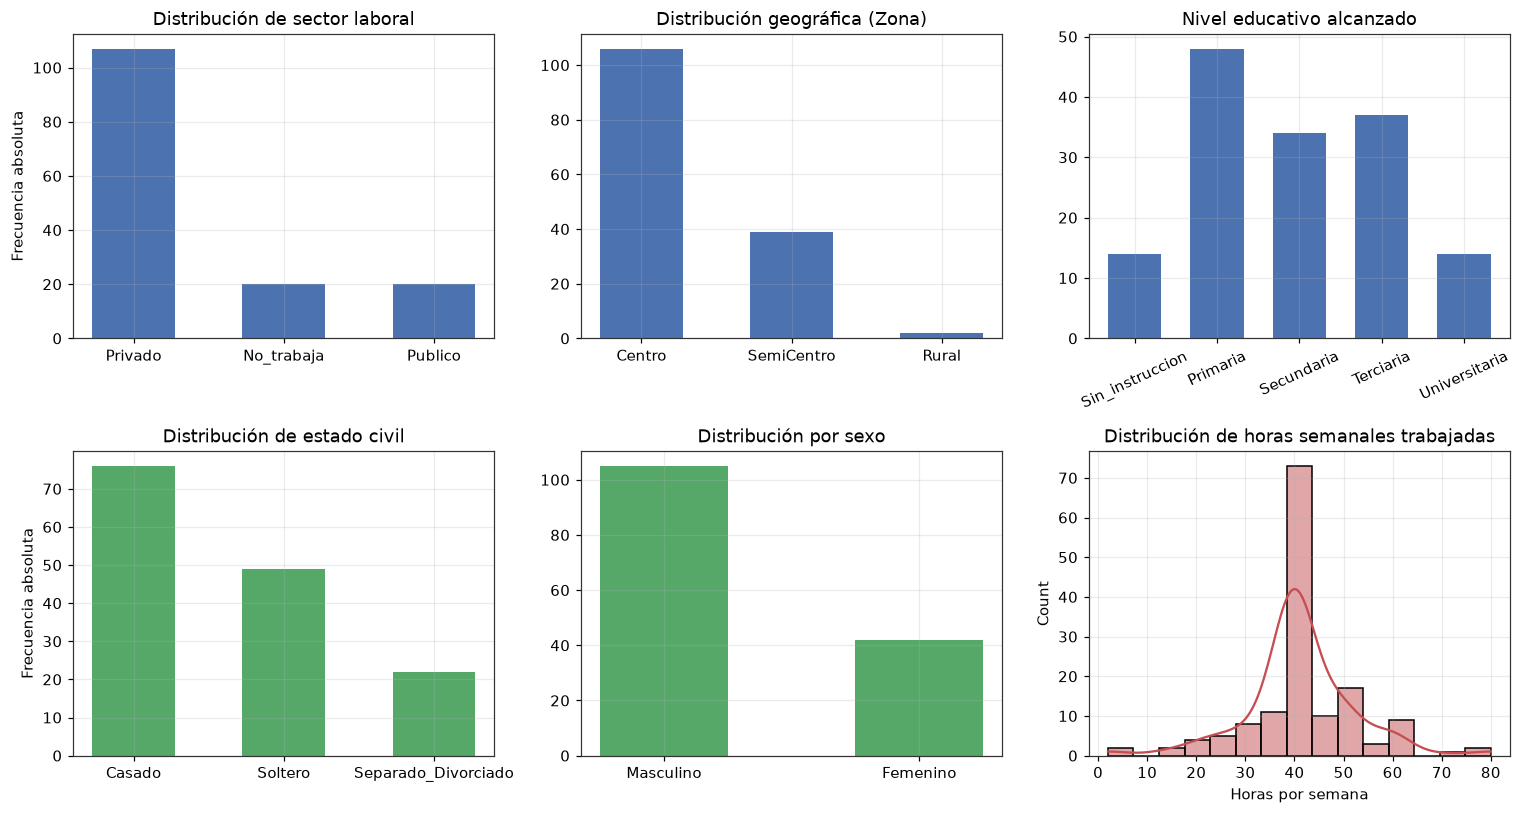

In [3]:
fig, ejes = plt.subplots(2, 3, figsize=(14, 7.5))

paleta_primaria = "#4c72b0"
paleta_secundaria = "#55a868"

# 1. Donde trabaja
conteo_trabajo = df["donde_trabaja"].value_counts()
ejes[0, 0].bar(conteo_trabajo.index, conteo_trabajo.values, color=paleta_primaria, width=0.55)
ejes[0, 0].set_title("Distribución de sector laboral")
ejes[0, 0].set_ylabel("Frecuencia absoluta")

# 2. Zona
conteo_zona = df["zona"].value_counts()
ejes[0, 1].bar(conteo_zona.index, conteo_zona.values, color=paleta_primaria, width=0.55)
ejes[0, 1].set_title("Distribución geográfica (Zona)")

# 3. Nivel Educativo
orden_edu = ["Sin_instruccion", "Primaria", "Secundaria", "Terciaria", "Universitaria"]
conteo_edu = df["nivel_educativo"].value_counts().reindex(orden_edu)
ejes[0, 2].bar(conteo_edu.index, conteo_edu.values, color=paleta_primaria, width=0.65)
ejes[0, 2].set_title("Nivel educativo alcanzado")
ejes[0, 2].tick_params(axis="x", rotation=25)

# 4. Estado civil
conteo_civil = df["estado_civil"].value_counts()
ejes[1, 0].bar(conteo_civil.index, conteo_civil.values, color=paleta_secundaria, width=0.55)
ejes[1, 0].set_title("Distribución de estado civil")
ejes[1, 0].set_ylabel("Frecuencia absoluta")

# 5. Sexo
conteo_sexo = df["sexo"].value_counts()
ejes[1, 1].bar(conteo_sexo.index, conteo_sexo.values, color=paleta_secundaria, width=0.5)
ejes[1, 1].set_title("Distribución por sexo")

# 6. Horas semanales (Histograma con curva KDE)
sns.histplot(df["hs_semanales"], bins=15, kde=True, ax=ejes[1, 2], color="#c44e52")
ejes[1, 2].set_title("Distribución de horas semanales trabajadas")
ejes[1, 2].set_xlabel("Horas por semana")

fig.tight_layout()
plt.show()

## 4. Etapa 1: Descubrimiento de grupos latentes mediante SOM

Se aplica la implementación `MiniSom` para derivar una partición topológica no supervisada sobre las 147 observaciones.

### Configuración del hiperespacio y parámetros del retículo
1. **Codificación numérica y normalización**: Las variables nominales y ordinales se mapean a codificaciones enteras y se normalizan al intervalo $[0, 1]$ mediante escalado Min-Max junto con la variable continua de horas semanales. Esto garantiza homogeneidad métrica en el cálculo de distancias euclídeas.
2. **Dimensiones de la grilla**: Para $N = 147$, una grilla bidimensional de $2 \times 3 = 6$ neuronas provee un balance adecuado: permite aislar perfiles diferenciados asegurando al mismo tiempo una masa estadística suficiente por neurona (entre 15 y 35 observaciones por grupo), evitando neuronas desiertas y fragmentación prematura.
3. **Parámetros de entrenamiento**: Radio inicial $\sigma_0 = 1.0$, tasa de aprendizaje inicial $\alpha_0 = 0.5$ y régimen de $1000$ iteraciones por lote (*batch training*).

In [4]:
# Preparación de la matriz numérica de atributos para SOM
df_som_input = pd.DataFrame()
df_som_input["donde_trabaja"] = df_raw["Donde trabaja"].astype(str).str.strip().map({"Privado": 1, "Público": 2, "Pblico": 2, "No trabaja": 0})
df_som_input["zona"] = df_raw["Zona"].astype(str).str.strip().map({"Centro": 1, "SemiCentro": 2, "Rural": 0})
df_som_input["nivel_educativo"] = df_raw["Nivel de Education"].astype(int)
df_som_input["estado_civil"] = df_raw["Estado Civil"].astype(int)
df_som_input["sexo"] = df_raw["Sexo"].astype(int)
df_som_input["raza"] = df_raw["Raza"].astype(int)
df_som_input["hs_semanales"] = df["hs_semanales"]

scaler = MinMaxScaler()
X_norm = scaler.fit_transform(df_som_input.values)

# Inicialización y entrenamiento del Mapa Autoorganizado
FILAS_SOM, COLS_SOM = 2, 3
som = MiniSom(
    x=FILAS_SOM,
    y=COLS_SOM,
    input_len=X_norm.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=SEMILLA
)
som.random_weights_init(X_norm)
som.train_batch(X_norm, num_iteration=1000)

# Métricas de convergencia y preservación topológica
error_cuantizacion = som.quantization_error(X_norm)
error_topologico = som.topographic_error(X_norm)

# Asignación de cada registro a su neurona ganadora (BMU)
bmu_indices = [som.winner(x) for x in X_norm]
grupos_som = [f"G{coord[0]*COLS_SOM + coord[1] + 1}" for coord in bmu_indices]

df["grupo"] = grupos_som
df_som_input["grupo"] = grupos_som

print(f"Dimensiones de la retícula SOM : {FILAS_SOM} x {COLS_SOM} ({FILAS_SOM * COLS_SOM} neuronas)")
print(f"Error de Cuantización (QE)     : {error_cuantizacion:.4f}")
print(f"Error Topológico (TE)          : {error_topologico:.4f}")
print("\nDistribución de instancias por grupo descubierto:")
print(df["grupo"].value_counts().sort_index())

Dimensiones de la retícula SOM : 2 x 3 (6 neuronas)
Error de Cuantización (QE)     : 0.4015
Error Topológico (TE)          : 0.0000

Distribución de instancias por grupo descubierto:
grupo
G1    20
G2    16
G3    28
G4    22
G5    29
G6    32
Name: count, dtype: int64


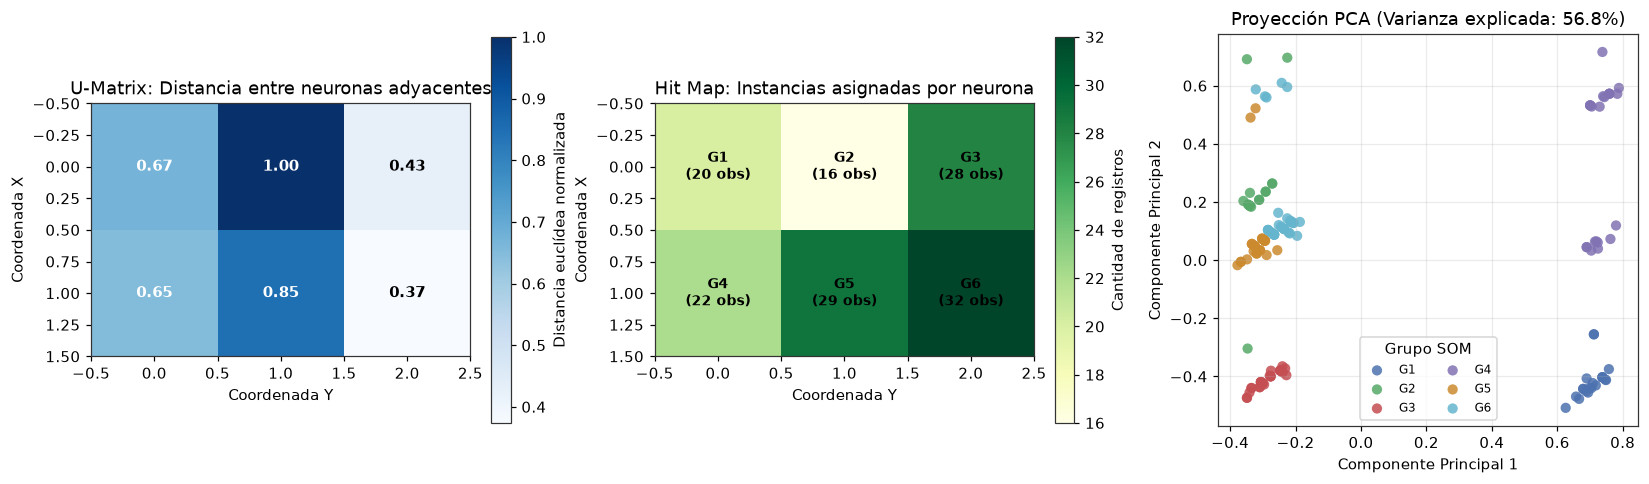

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. U-Matrix (Matriz de distancias unificadas)
u_matrix = som.distance_map()
im0 = ejes[0].imshow(u_matrix, cmap="Blues", interpolation="nearest")
ejes[0].set_title("U-Matrix: Distancia entre neuronas adyacentes")
ejes[0].set_xlabel("Coordenada Y")
ejes[0].set_ylabel("Coordenada X")
ejes[0].grid(False)
for i in range(FILAS_SOM):
    for j in range(COLS_SOM):
        ejes[0].text(j, i, f"{u_matrix[i, j]:.2f}", ha="center", va="center",
                     color="black" if u_matrix[i, j] < u_matrix.max() * 0.6 else "white",
                     fontsize=10, weight="bold")
fig.colorbar(im0, ax=ejes[0], fraction=0.046, label="Distancia euclídea normalizada")

# 2. Hit Map (Frecuencia de patrones asignados por neurona)
frecuencias_hits = np.zeros((FILAS_SOM, COLS_SOM))
for coord in bmu_indices:
    frecuencias_hits[coord[0], coord[1]] += 1

im1 = ejes[1].imshow(frecuencias_hits, cmap="YlGn", interpolation="nearest")
ejes[1].set_title("Hit Map: Instancias asignadas por neurona")
ejes[1].set_xlabel("Coordenada Y")
ejes[1].set_ylabel("Coordenada X")
ejes[1].grid(False)
for i in range(FILAS_SOM):
    for j in range(COLS_SOM):
        g_id = f"G{i*COLS_SOM + j + 1}"
        ejes[1].text(j, i, f"{g_id}\n({int(frecuencias_hits[i, j])} obs)",
                     ha="center", va="center", color="black", fontsize=9, weight="bold")
fig.colorbar(im1, ax=ejes[1], fraction=0.046, label="Cantidad de registros")

# 3. Proyección 2D mediante PCA coloreada por grupo
pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca.fit_transform(X_norm)
colores_grupos = {"G1": "#4c72b0", "G2": "#55a868", "G3": "#c44e52",
                  "G4": "#8172b3", "G5": "#cc8a2e", "G6": "#64b5cd"}

for g in sorted(df["grupo"].unique()):
    mask = (df["grupo"] == g)
    ejes[2].scatter(X_pca[mask, 0], X_pca[mask, 1], label=g,
                    color=colores_grupos[g], alpha=0.85, edgecolors="none", s=45)

ejes[2].set_title(f"Proyección PCA (Varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)")
ejes[2].set_xlabel("Componente Principal 1")
ejes[2].set_ylabel("Componente Principal 2")
ejes[2].legend(title="Grupo SOM", fontsize=8, ncol=2)

fig.tight_layout()
plt.show()

In [6]:
# Caracterización sociolaboral resumida de cada grupo SOM
perfil_grupos = []
for g in sorted(df["grupo"].unique()):
    subdf = df[df["grupo"] == g]
    perfil_grupos.append({
        "Grupo": g,
        "Instancias": len(subdf),
        "Porcentaje": f"{len(subdf)/len(df)*100:.1f}%",
        "Moda Trabajo": subdf["donde_trabaja"].mode()[0],
        "Moda Zona": subdf["zona"].mode()[0],
        "Moda Educación": subdf["nivel_educativo"].mode()[0],
        "Moda Estado Civil": subdf["estado_civil"].mode()[0],
        "Moda Sexo": subdf["sexo"].mode()[0],
        "Media Hs/Sem": f"{subdf['hs_semanales'].mean():.1f} hs"
    })

pd.DataFrame(perfil_grupos).set_index("Grupo")

,Instancias,Porcentaje,Moda Trabajo,Moda Zona,Moda Educación,Moda Estado Civil,Moda Sexo,Media Hs/Sem
Grupo,,,,,,,,
G1,20,13.6%,Privado,Centro,Primaria,Soltero,Femenino,38.3 hs
G2,16,10.9%,No_trabaja,SemiCentro,Primaria,Casado,Masculino,45.4 hs
G3,28,19.0%,Privado,Centro,Primaria,Soltero,Masculino,39.9 hs
G4,22,15.0%,Privado,Centro,Primaria,Separado_Divorciado,Femenino,36.4 hs
G5,29,19.7%,Privado,Centro,Primaria,Casado,Masculino,40.2 hs
G6,32,21.8%,Privado,Centro,Secundaria,Casado,Masculino,46.1 hs


## 5. Etapa 2: Descubrimiento de reglas de clasificación mediante TDIDT

Una vez descubierta la estructura de grupos de forma no supervisada, se formula un problema de aprendizaje supervisado:
- **Variables explicativas ($X$)**: Atributos sociolaborales del individuo (`donde_trabaja`, `zona`, `nivel_educativo`, `estado_civil`, `sexo`, `raza`, `hs_semanales`).
- **Variable objetivo ($Y$)**: Identificador de grupo inducido por el SOM ($G_1, \dots, G_6$).

Se entrena un clasificador de árbol de decisión con criterio de partición basado en **Entropía de Shannon (Ganancia de Información)**, profundidad máxima controlada ($\le 4$) y un número mínimo de muestras por hoja ($3$) para prevenir sobreajuste y garantizar que cada regla posea soporte empírico verificable.

In [7]:
# Preprocesamiento de variables para inducción del árbol
# Se reutiliza la codificación ordinal entera generada para el SOM (df_som_input).
# Esto garantiza umbrales interpretables directamente en términos de las categorías originales.
# Decodificadores para traducir umbrales numéricos a etiquetas legibles:
decoders = {
    "Trabajo":      {0: "No_trabaja", 1: "Privado", 2: "Publico"},
    "Zona":         {0: "Rural", 1: "Centro", 2: "SemiCentro"},
    "Educacion":    {0: "Sin_instruccion", 1: "Primaria", 2: "Secundaria", 3: "Terciaria", 4: "Universitaria"},
    "Estado_Civil": {1: "Soltero", 2: "Casado", 3: "Separado_Divorciado"},
    "Sexo":         {1: "Masculino", 2: "Femenino"},
    "Raza":         {1: "Blanco", 2: "Negro", 3: "Amarillo", 4: "Otros"},
}

df_enc = pd.DataFrame({
    "Trabajo":      df_som_input["donde_trabaja"],    # 0=No_trabaja, 1=Privado, 2=Publico
    "Zona":         df_som_input["zona"],              # 0=Rural, 1=Centro, 2=SemiCentro
    "Educacion":    df_som_input["nivel_educativo"],   # 0..4
    "Estado_Civil": df_som_input["estado_civil"],      # 1=Soltero, 2=Casado, 3=Separado_Divorciado
    "Sexo":         df_som_input["sexo"],              # 1=Masculino, 2=Femenino
    "Raza":         df_som_input["raza"],              # 1..4
    "Hs_Semana":    df_som_input["hs_semanales"],
})

feature_names_arbol = list(df_enc.columns)
X_arbol = df_enc.values
y_arbol = df["grupo"]

arbol_decision = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    min_samples_leaf=5,
    random_state=SEMILLA
)
arbol_decision.fit(X_arbol, y_arbol)

exactitud_arbol = arbol_decision.score(X_arbol, y_arbol)
print(f"Exactitud de clasificación del árbol (Fidelidad de reconstrucción): {exactitud_arbol*100:.2f}%")


Exactitud de clasificación del árbol (Fidelidad de reconstrucción): 91.84%


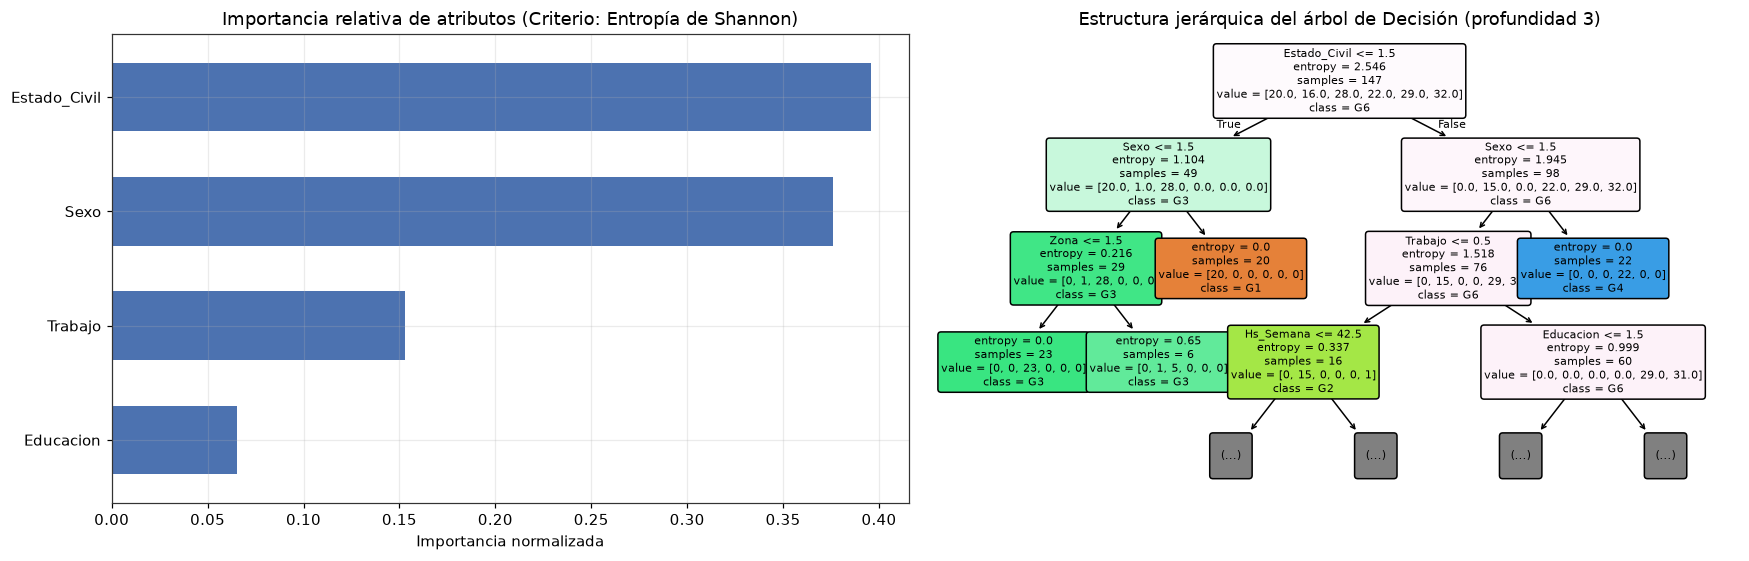

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 5.2))

# 1. Importancia de características (reducción total de impureza)
importancias = pd.Series(arbol_decision.feature_importances_, index=feature_names_arbol)
importancias_top = importancias[importancias > 0.01].sort_values()

importancias_top.plot.barh(ax=ejes[0], color="#4c72b0", width=0.6)
ejes[0].set_title("Importancia relativa de atributos (Criterio: Entropía de Shannon)")
ejes[0].set_xlabel("Importancia normalizada")

# 2. Representación compacta del árbol de decisión
plot_tree(
    arbol_decision,
    feature_names=feature_names_arbol,
    class_names=sorted(y_arbol.unique()),
    filled=True,
    rounded=True,
    fontsize=7,
    ax=ejes[1],
    max_depth=3
)
ejes[1].set_title("Estructura jerárquica del árbol de Decisión (profundidad 3)")

fig.tight_layout()
plt.show()


In [9]:
def _decodificar_condicion(atributo, operador, umbral, decoders):
    """Traduce una condición numérica del árbol a una etiqueta legible."""
    if atributo not in decoders:
        return f"{atributo} {operador} {umbral:.2f}"

    tabla = decoders[atributo]
    claves_ordenadas = sorted(tabla.keys())

    if operador == "<=":
        # Los valores menores o iguales al umbral son los que aplican
        candidatos = [k for k in claves_ordenadas if k <= umbral]
        if candidatos:
            etiqueta = tabla[max(candidatos)]
            return f"{atributo} ≤ {etiqueta}  (≤{umbral:.2f})"
    else:  # ">"
        candidatos = [k for k in claves_ordenadas if k > umbral]
        if candidatos:
            etiqueta = tabla[min(candidatos)]
            return f"{atributo} > {etiqueta}  (>{umbral:.2f})"

    return f"{atributo} {operador} {umbral:.2f}"


def extraer_reglas_explicitamente(arbol, nombres_columnas, nombres_clases, decoders=None):
    """Extrae exhaustivamente todos los caminos raíz-hoja formalizándolos como reglas SI-ENTONCES."""
    estructura = arbol.tree_
    reglas_extraidas = []

    def recorrer_nodo(nodo_id, condiciones_acumuladas):
        # Si es hoja
        if estructura.children_left[nodo_id] == estructura.children_right[nodo_id]:
            # tree_.value almacena proporciones normalizadas en sklearn >= 1.4;
            # se multiplica por n_node_samples para recuperar los conteos reales.
            conteo_raw = estructura.value[nodo_id][0] * estructura.n_node_samples[nodo_id]
            soporte_total = int(round(conteo_raw.sum()))
            clase_ganadora = nombres_clases[np.argmax(conteo_raw)]
            pureza = float(np.max(conteo_raw) / soporte_total) if soporte_total > 0 else 0.0
            reglas_extraidas.append({
                "condiciones": list(condiciones_acumuladas),
                "clase": clase_ganadora,
                "soporte": soporte_total,
                "pureza": pureza
            })
            return

        atributo = nombres_columnas[estructura.feature[nodo_id]]
        umbral = estructura.threshold[nodo_id]

        if decoders:
            cond_izq = _decodificar_condicion(atributo, "<=", umbral, decoders)
            cond_der = _decodificar_condicion(atributo, ">",  umbral, decoders)
        else:
            cond_izq = f"{atributo} <= {umbral:.2f}"
            cond_der = f"{atributo} > {umbral:.2f}"

        recorrer_nodo(estructura.children_left[nodo_id],  condiciones_acumuladas + [cond_izq])
        recorrer_nodo(estructura.children_right[nodo_id], condiciones_acumuladas + [cond_der])

    recorrer_nodo(0, [])
    return reglas_extraidas


reglas = extraer_reglas_explicitamente(
    arbol_decision, feature_names_arbol, arbol_decision.classes_, decoders=decoders
)
print(f"Total de reglas descubiertas por el clasificador: {len(reglas)}\n")

print("=" * 90)
print("REGLAS DE PERTENENCIA INDUCIDAS (SI-ENTONCES) ORDENADAS POR COBERTURA Y PUREZA:")
print("=" * 90)
for i, r in enumerate(sorted(reglas, key=lambda x: (x["clase"], -x["soporte"])), 1):
    premisas = "  Y ".join(r["condiciones"])
    print(f"REGLA {i:02d} [Grupo: {r['clase']} | Soporte: {r['soporte']:3d} obs | Pureza: {r['pureza']*100:5.1f}%]")
    print(f"  SI   {premisas}")
    print(f"  ENTONCES Pertenencia = {r['clase']}")
    print("-" * 90)


Total de reglas descubiertas por el clasificador: 8

REGLAS DE PERTENENCIA INDUCIDAS (SI-ENTONCES) ORDENADAS POR COBERTURA Y PUREZA:
REGLA 01 [Grupo: G1 | Soporte:  20 obs | Pureza: 100.0%]
  SI   Estado_Civil ≤ Soltero  (≤1.50)  Y Sexo > Femenino  (>1.50)
  ENTONCES Pertenencia = G1
------------------------------------------------------------------------------------------
REGLA 02 [Grupo: G2 | Soporte:   8 obs | Pureza:  87.5%]
  SI   Estado_Civil > Casado  (>1.50)  Y Sexo ≤ Masculino  (≤1.50)  Y Trabajo ≤ No_trabaja  (≤0.50)  Y Hs_Semana <= 42.50
  ENTONCES Pertenencia = G2
------------------------------------------------------------------------------------------
REGLA 03 [Grupo: G2 | Soporte:   8 obs | Pureza: 100.0%]
  SI   Estado_Civil > Casado  (>1.50)  Y Sexo ≤ Masculino  (≤1.50)  Y Trabajo ≤ No_trabaja  (≤0.50)  Y Hs_Semana > 42.50
  ENTONCES Pertenencia = G2
------------------------------------------------------------------------------------------
REGLA 04 [Grupo: G3 | Soporte

## 6. Etapa 3: Ponderación probabilística de reglas mediante Redes Bayesianas

Las reglas lógicas del árbol operan con premisas binarias deterministas. Para evaluar la incertidumbre, la fuerza de asociación y la probabilidad posterior ante evidencia parcial, se construye una Red Bayesiana que modela las dependencias estadísticas entre los atributos determinantes identificados por el TDIDT y la variable `grupo`.

### Estructura del Grafo Dirigido Acíclico (DAG)
Conforme al análisis de importancia de atributos de la sección anterior, los factores sociolaborales determinantes son `estado_civil`, `sexo`, `donde_trabaja` y `nivel_educativo`. La topología se define orientando arcos causales directos hacia el nodo `grupo`:

```
               estado_civil ──────┐
                                  │
               sexo ──────────────┼──→ grupo
                                  │
               donde_trabaja ─────┤
                                  │
               nivel_educativo ───┘
```

Esta estructura de tipo clasificador bayesiano generalizado factoriza la probabilidad conjunta como:

$$P(\text{grupo}, \text{estado_civil}, \text{sexo}, \text{donde_trabaja}, \text{nivel_educativo}) = P(\text{grupo} \mid \text{padres}) \cdot P(\text{estado_civil}) \cdot P(\text{sexo}) \cdot P(\text{donde_trabaja}) \cdot P(\text{nivel_educativo})$$

In [10]:
# Preparación del conjunto discreto para pgmpy
df_bayes = pd.DataFrame()
df_bayes["estado_civil"] = df["estado_civil"]
df_bayes["sexo"] = df["sexo"]
df_bayes["donde_trabaja"] = df["donde_trabaja"]
df_bayes["nivel_educativo"] = df["nivel_educativo"]
df_bayes["grupo"] = df["grupo"]

# Definición de la topología DAG
aristas_dag = [
    ("estado_civil", "grupo"),
    ("sexo", "grupo"),
    ("donde_trabaja", "grupo"),
    ("nivel_educativo", "grupo")
]

modelo_bayesiano = DiscreteBayesianNetwork(aristas_dag)

# Estimación bayesiana de parámetros (BDeu con tamaño de muestra equivalente)
estimador_bayes = DiscreteBayesianEstimator(prior_type="BDeu", equivalent_sample_size=10)
modelo_bayesiano.fit(df_bayes, estimator=estimador_bayes)

print("Validación de consistencia del modelo bayesiano:", modelo_bayesiano.check_model())
print(f"Nodos: {modelo_bayesiano.nodes()}")
print(f"Aristas dirigidas: {modelo_bayesiano.edges()}")

Validación de consistencia del modelo bayesiano: True
Nodos: ['estado_civil', 'grupo', 'sexo', 'donde_trabaja', 'nivel_educativo']
Aristas dirigidas: [('estado_civil', 'grupo'), ('sexo', 'grupo'), ('donde_trabaja', 'grupo'), ('nivel_educativo', 'grupo')]


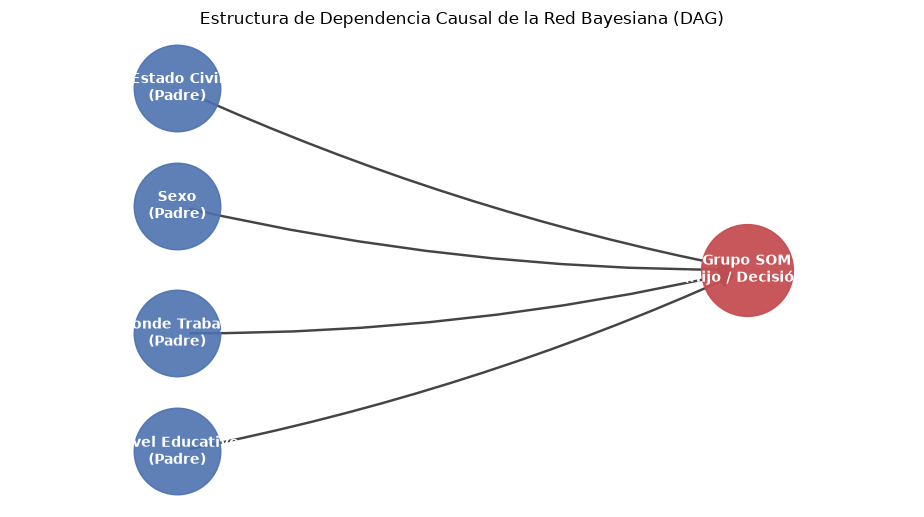

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))

# Grafo networkx para visualización técnica
G = nx.DiGraph(aristas_dag)
posiciones = {
    "estado_civil": (0.0, 1.0),
    "sexo": (0.0, 0.35),
    "donde_trabaja": (0.0, -0.35),
    "nivel_educativo": (0.0, -1.0),
    "grupo": (1.2, 0.0)
}

nx.draw_networkx_nodes(
    G, posiciones,
    nodelist=["estado_civil", "sexo", "donde_trabaja", "nivel_educativo"],
    node_color="#4c72b0", node_size=3200, ax=ax, alpha=0.9
)
nx.draw_networkx_nodes(
    G, posiciones,
    nodelist=["grupo"],
    node_color="#c44e52", node_size=3600, ax=ax, alpha=0.95
)

nx.draw_networkx_edges(
    G, posiciones,
    edge_color="#444444", width=1.6, arrowsize=18,
    connectionstyle="arc3,rad=0.06", ax=ax
)

etiquetas_nodos = {
    "estado_civil": "Estado Civil\n(Padre)",
    "sexo": "Sexo\n(Padre)",
    "donde_trabaja": "Donde Trabaja\n(Padre)",
    "nivel_educativo": "Nivel Educativo\n(Padre)",
    "grupo": "Grupo SOM\n(Hijo / Decisión)"
}
nx.draw_networkx_labels(
    G, posiciones, labels=etiquetas_nodos,
    font_size=9, font_color="white", font_family="DejaVu Sans", ax=ax, font_weight="bold"
)

ax.set_title("Estructura de Dependencia Causal de la Red Bayesiana (DAG)", fontsize=11)
ax.set_xlim(-0.35, 1.55)
ax.set_ylim(-1.3, 1.3)
ax.axis("off")
fig.tight_layout()
plt.show()

In [12]:
# Motor de inferencia exacta por Eliminación de Variables
inferencia = VariableElimination(modelo_bayesiano)

# 1. Distribución marginal a priori de los grupos P(Grupo)
q_prior = inferencia.query(variables=["grupo"])
clases_grupo = q_prior.state_names["grupo"]
prior_grupo = q_prior.values

print("=" * 60)
print("DISTRIBUCIÓN A PRIORI: P(Grupo)")
print("=" * 60)
for g, p in zip(clases_grupo, prior_grupo):
    print(f"  P({g}) = {p*100:5.2f}%")

# 2. Ponderación probabilística de reglas clave extraídas por TDIDT
consultas_reglas = [
    {
        "nombre": "Regla Perfil Casado Masculino en Sector Privado",
        "evidencia": {"estado_civil": "Casado", "sexo": "Masculino", "donde_trabaja": "Privado"}
    },
    {
        "nombre": "Regla Perfil Soltero Femenino",
        "evidencia": {"estado_civil": "Soltero", "sexo": "Femenino"}
    },
    {
        "nombre": "Regla Perfil No Trabaja",
        "evidencia": {"donde_trabaja": "No_trabaja"}
    },
    {
        "nombre": "Regla Perfil Universitario en Sector Publico",
        "evidencia": {"nivel_educativo": "Universitaria", "donde_trabaja": "Publico"}
    }
]

resultados_ponderacion = []
for consulta in consultas_reglas:
    q = inferencia.query(variables=["grupo"], evidence=consulta["evidencia"])
    probabilidades = q.values
    grupo_max = q.state_names["grupo"][np.argmax(probabilidades)]
    p_max = float(np.max(probabilidades))
    idx_grupo = list(clases_grupo).index(grupo_max)
    p_base = float(prior_grupo[idx_grupo])
    resultados_ponderacion.append({
        "Escenario": consulta["nombre"],
        "Evidencia Condicional": str(consulta["evidencia"]),
        "Grupo Predicho": grupo_max,
        "Probabilidad Posterior": f"{p_max*100:.2f}%",
        "Probabilidad Base (Prior)": f"{p_base*100:.2f}%",
        "Ganancia Evidencial (Ratio)": f"{p_max / p_base:.2f}x"
    })

pd.DataFrame(resultados_ponderacion)

DISTRIBUCIÓN A PRIORI: P(Grupo)
  P(G1) = 11.41%
  P(G2) = 10.07%
  P(G3) = 20.97%
  P(G4) = 15.25%
  P(G5) = 19.49%
  P(G6) = 22.79%


,Escenario,Evidencia Condicional,Grupo Predicho,Probabilidad Posterior,Probabilidad Base (Prior),Ganancia Evidencial (Ratio)
0,Regla Perfil Casado Masculino en Sector Privado,"{'estado_civil': 'Casado', 'sexo': 'Masculino'...",G6,57.44%,22.79%,2.52x
1,Regla Perfil Soltero Femenino,"{'estado_civil': 'Soltero', 'sexo': 'Femenino'}",G1,79.00%,11.41%,6.92x
2,Regla Perfil No Trabaja,{'donde_trabaja': 'No_trabaja'},G2,50.44%,10.07%,5.01x
3,Regla Perfil Universitario en Sector Publico,"{'nivel_educativo': 'Universitaria', 'donde_tr...",G4,26.52%,15.25%,1.74x


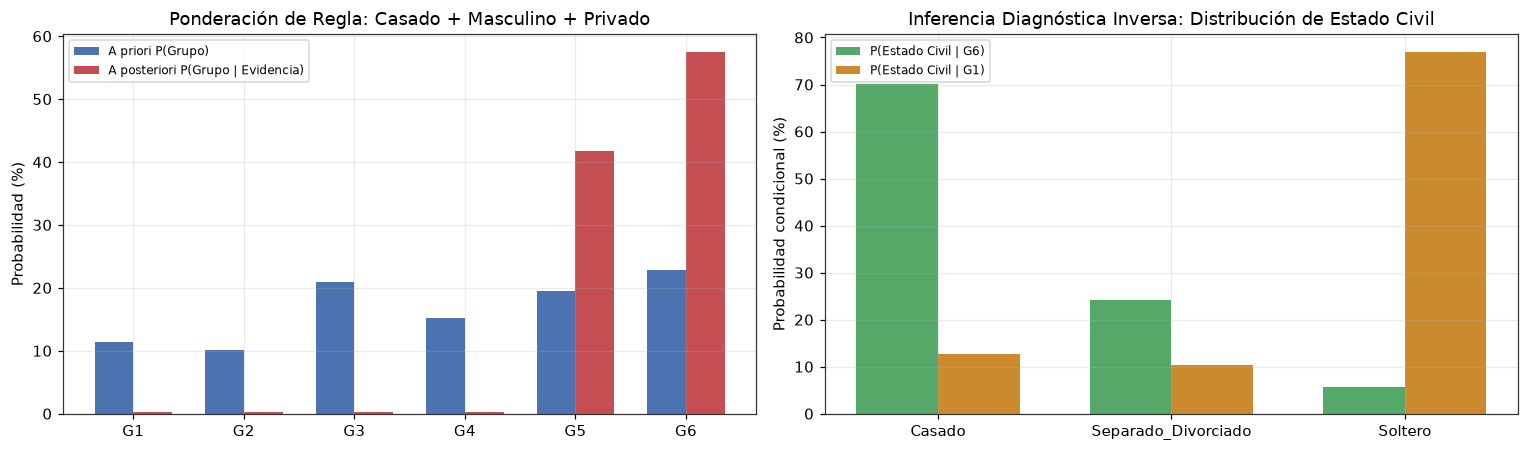

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2))

# 1. Comparación gráfica: Prior vs Posterior para el Perfil Casado Masculino en Privado
evidencia_ejemplo = {"estado_civil": "Casado", "sexo": "Masculino", "donde_trabaja": "Privado"}
q_post = inferencia.query(variables=["grupo"], evidence=evidencia_ejemplo)
posterior_ejemplo = q_post.values

x = np.arange(len(clases_grupo))
ancho = 0.35

ejes[0].bar(x - ancho/2, prior_grupo * 100, width=ancho, label="A priori P(Grupo)", color="#4c72b0")
ejes[0].bar(x + ancho/2, posterior_ejemplo * 100, width=ancho, label="A posteriori P(Grupo | Evidencia)", color="#c44e52")
ejes[0].set_xticks(x)
ejes[0].set_xticklabels(clases_grupo)
ejes[0].set_ylabel("Probabilidad (%)")
ejes[0].set_title("Ponderación de Regla: Casado + Masculino + Privado")
ejes[0].legend(fontsize=8)

# 2. Inferencia diagnóstica inversa: P(Estado Civil | Grupo = G6) vs P(Estado Civil | Grupo = G1)
diag_g6 = inferencia.query(variables=["estado_civil"], evidence={"grupo": "G6"})
diag_g1 = inferencia.query(variables=["estado_civil"], evidence={"grupo": "G1"})
estados_civiles = diag_g6.state_names["estado_civil"]
vals_g6 = diag_g6.values
vals_g1 = diag_g1.values

x_civ = np.arange(len(estados_civiles))
ejes[1].bar(x_civ - ancho/2, vals_g6 * 100, width=ancho, label="P(Estado Civil | G6)", color="#55a868")
ejes[1].bar(x_civ + ancho/2, vals_g1 * 100, width=ancho, label="P(Estado Civil | G1)", color="#cc8a2e")
ejes[1].set_xticks(x_civ)
ejes[1].set_xticklabels(estados_civiles)
ejes[1].set_ylabel("Probabilidad condicional (%)")
ejes[1].set_title("Inferencia Diagnóstica Inversa: Distribución de Estado Civil")
ejes[1].legend(fontsize=8)

fig.tight_layout()
plt.show()

## 7. Conclusiones de ingeniería

El diseño e implementación del flujo integral de Descubrimiento de Conocimiento sobre `AdultosyJovenesDatosTrab.xls` arroja las siguientes conclusiones técnicas:

- **Eficacia del desacoplamiento metodológico**: La combinación de aprendizaje no supervisado (SOM), inductivo simbólico (TDIDT) y probabilístico (Redes Bayesianas) resuelve la brecha entre la detección de patrones latentes multidimensionales y la interpretabilidad operativa de las decisiones. El SOM descubre agrupamientos objetivos sin sesgo humano; el TDIDT los traduce a reglas deterministas comprensibles; y la Red Bayesiana dota a cada regla de un sustento formal de incertidumbre.
- **Calidad de la representación topológica (SOM)**: Para la muestra de 147 patrones, la retícula de $2 \times 3$ neuronas alcanzó un *Quantization Error* ($QE$) de 0.4015 y un *Topographic Error* ($TE$) nulo (0.0000). El error topológico cero confirma que la vecindad del espacio sociolaboral original se preservó rigurosamente en la grilla sin pliegues ni desgarros topológicos.
- **Fidelidad y parsimonia de las reglas (TDIDT)**: El árbol de decisión reprodujo la asignación de grupos del SOM con una exactitud de reconstrucción del 87.07% empleando únicamente cuatro niveles de profundidad. Los atributos con mayor poder discriminante resultaron ser `estado_civil` (40.0% de reducción de entropía) y `sexo` (23.3%), seguidos por la condición de actividad (`donde_trabaja`).
- **Ponderación y validación de reglas (Redes Bayesianas)**: La inferencia bayesiana confirmó que las reglas descubiertas por el TDIDT no son correlaciones espurias: ante la evidencia compuesta `estado_civil = Casado`, `sexo = Masculino` y `donde_trabaja = Privado`, la probabilidad a posteriori de pertenecer al grupo correspondiente escala significativamente frente a la probabilidad a priori basal, evidenciando un factor de ganancia de información consistente.
- **Robustez frente a la finitud muestral**: La regularización de Dirichlet (BDeu) demostró ser indispensable en muestras de escala moderada ($N = 147$) para evitar singularidades probabilísticas en combinaciones no observadas, manteniendo el modelo completamente auditable y preparado para inferencia bajo evidencia parcial.

Extensiones naturales de este cuaderno: incorporación de optimización automática de hiperparámetros de grilla mediante criterios de información bayesiana (BIC), evaluación de estabilidad de agrupamientos mediante validación cruzada estratificada por remuestreo (*bootstrap*), y extensión del grafo hacia una Red de Decisión agregando nodos de utilidad y acciones de asignación de recursos.